# 01 · Data Preparation: making NYC 311 AI-ready for every component
Civic Operations · NUS ISS IRS Practice Module · Group 23

> ## ⚠️ READ ME FIRST: every team member goes through this notebook before building their component
> It explains **where every table comes from, what is real vs synthetic, which component uses which table, and the rules that stop label leakage**. It runs on any laptop (CPU).
>
> **Before you start:** `py -m pip install -r requirements-ml.txt` from the repo root.
> **Rule:** do NOT change the shared tables or the synthetic population on your own. If you need a change, raise a
> *Data / Contract Change Request* issue on GitHub so all four of us agree (see `05_Team_Workspace/`).

## What this notebook does
| Step | Script | Output | Real or synthetic |
|---|---|---|---|
| 1 Download | `data/pipeline/download.py` | `data/raw/*.csv` (git-ignored) | Real (NYC Open Data, Open-Meteo) |
| 2 Clean + label | `data/pipeline/clean.py` | `requests_real.parquet` | Real |
| 2b Aggregates | `data/pipeline/aggregates.py` | `daily_demand_weather.parquet`, `reference/demand_baselines.csv` | Real |
| 3 Synthetic population | `data/pipeline/synthetic.py` | `synthetic_*.parquet` | **Synthetic, labelled** |
| 4 NLP data | `data/pipeline/nlp_data.py` | `synthetic_nlp_utterances.parquet` | **Synthetic**; the gold test set is hand-written |

All logic lives in the scripts (so it is testable and identical for everybody); this notebook runs them and **shows** the data.
Seed = 2026, so everyone who runs it gets the same tables.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "01_Application" / "data" / "pipeline").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "01_Application")); sys.path.insert(0, str(ROOT / "packages" / "contracts"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
P = ROOT / "01_Application" / "data" / "processed"; R = ROOT / "01_Application" / "data" / "reference"
print("repo:", ROOT)

repo: D:\NUS-Projects\IRS-Project-Details


## 1 · Run the pipeline
The download is skipped when files already exist. The first full run takes 1–3 hours (the 2020+ daily counts are aggregated on NYC's server). Set `RUN = False` to only load existing tables.

In [2]:
RUN = False   # True = (re)build everything from data/raw
if RUN:
    from data.pipeline import build
    import sys; sys.argv = ["build"]; build.main()
import json
manifest = json.loads((P / "manifest.json").read_text()) if (P / "manifest.json").exists() else {"tables": []}
pd.DataFrame(manifest["tables"])

,file,rows,columns,sha256_16,is_synthetic
0,daily_demand_weather.parquet,97411,12,06ba416685e3892c,False
1,requests_real.parquet,49558,54,6a5ee39f87287f2a,False
2,synthetic_burst_requests.parquet,1391,16,f35beb122153d58a,True
3,synthetic_citizens.parquet,5000,11,1382adcb251a44f7,True
4,synthetic_crews.parquet,136,11,cac25e2b2fed48bf,True
5,synthetic_nlp_utterances.parquet,18654,11,3fc9a8a37ab752a4,True
6,synthetic_queue_snapshots.parquet,10348,23,b4c5f93ec5e5ac3b,True
7,synthetic_reporter_links.parquet,49558,3,26b2a3a8039849fc,True
8,synthetic_urgency_scenarios.parquet,1000,20,d854ff81749f040a,True


## 2 · The real requests: 5 boroughs × up to 10,000 rows
Sampled as **random time windows** across the last 12 months (not random rows). A window keeps every report made in those hours, so duplicates of one incident stay together for C05, and the windows still cover every season and hour.

In [3]:
real = pd.read_parquet(P / "requests_real.parquet")
print(f"{len(real):,} real rows, {real.request_type_code.nunique()} request types, {real.created_at.min():%d %b %Y} to {real.created_at.max():%d %b %Y}")
real.groupby(["borough", "complaint_family"]).size().unstack(fill_value=0)

49,558 real rows, 34 request types, 24 Sep 2025 to 16 Sep 2026


complaint_family,BUILDINGS,HEALTH,HOUSING,NOISE_PARKING,PARKS_TREES,SANITATION,STREETS,WATER_SEWER
borough,,,,,,,,
BRONX,199,60,3308,4967,69,489,389,502
BROOKLYN,221,82,2324,4619,306,1248,797,383
MANHATTAN,250,106,2864,4922,87,569,827,282
QUEENS,173,72,1002,5726,405,994,1182,421
STATEN ISLAND,211,87,859,3336,772,1912,1807,729


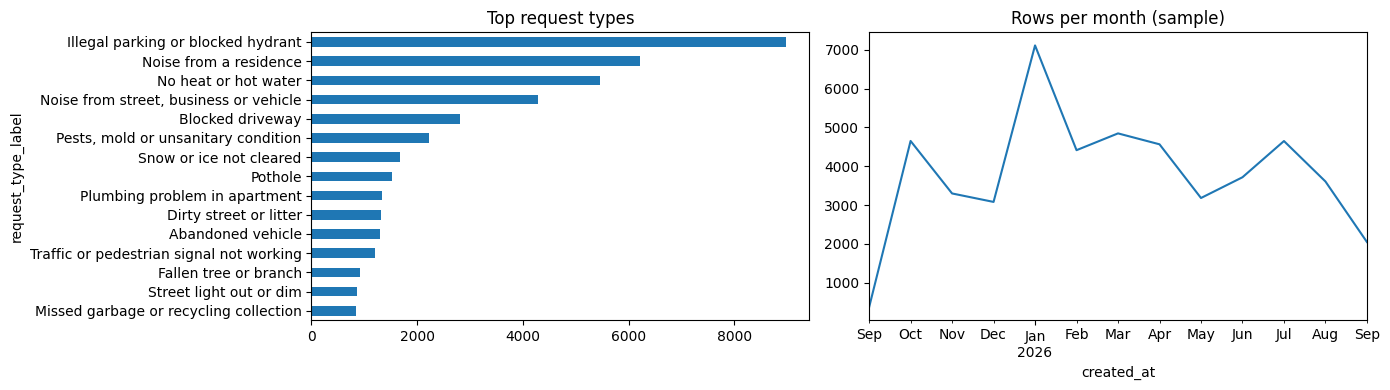

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
real.request_type_label.value_counts().head(15).plot.barh(ax=ax[0], title="Top request types"); ax[0].invert_yaxis()
real.groupby(real.created_at.dt.to_period("M")).size().plot(ax=ax[1], title="Rows per month (sample)")
plt.tight_layout()

## 3 · Labels built from real data, and what they mean
**`outcome_class`** comes from the crew's closing note (`resolution_description`), using ordered per-agency rules in `clean.py`. It is a **proxy**: it records what the crew *found*, not what the citizen *intended*.

* `verified_outcome` = GENUINE (GENUINE or SUBSIDED) · UNFOUNDED · INCONCLUSIVE (everything else)
* Caveat: NYPD noise and parking calls often close as 'no evidence of violation' because the car or the noise had already gone. Weigh this in C06/C07.
* `resolution_hours` (C09 target) is only valid where `resolution_valid` is True (closed, 0–120 days, not duplicate or administrative).

In [5]:
pd.crosstab(real.agency, real.outcome_class, normalize="index").round(2)

outcome_class,ADMINISTRATIVE,DUPLICATE,GENUINE,NO_ACCESS,NO_NOTE,REFERRED,SUBSIDED,UNFOUNDED
agency,,,,,,,,
DEP,0.16,0.22,0.29,0.00,0.01,0.04,0.06,0.23
DOB,0.32,0.04,0.15,0.09,0.00,0.02,0.00,0.38
DOHMH,0.05,0.31,0.24,0.08,0.14,0.02,0.00,0.16
DOT,0.51,0.08,0.22,0.00,0.04,0.07,0.00,0.07
DPR,0.17,0.00,0.49,0.03,0.07,0.05,0.00,0.19
DSNY,0.16,0.02,0.35,0.00,0.01,0.06,0.02,0.38
HPD,0.11,0.17,0.12,0.24,0.00,0.00,0.18,0.18
NYC311-PRD,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
NYPD,0.01,0.00,0.16,0.03,0.00,0.01,0.24,0.54


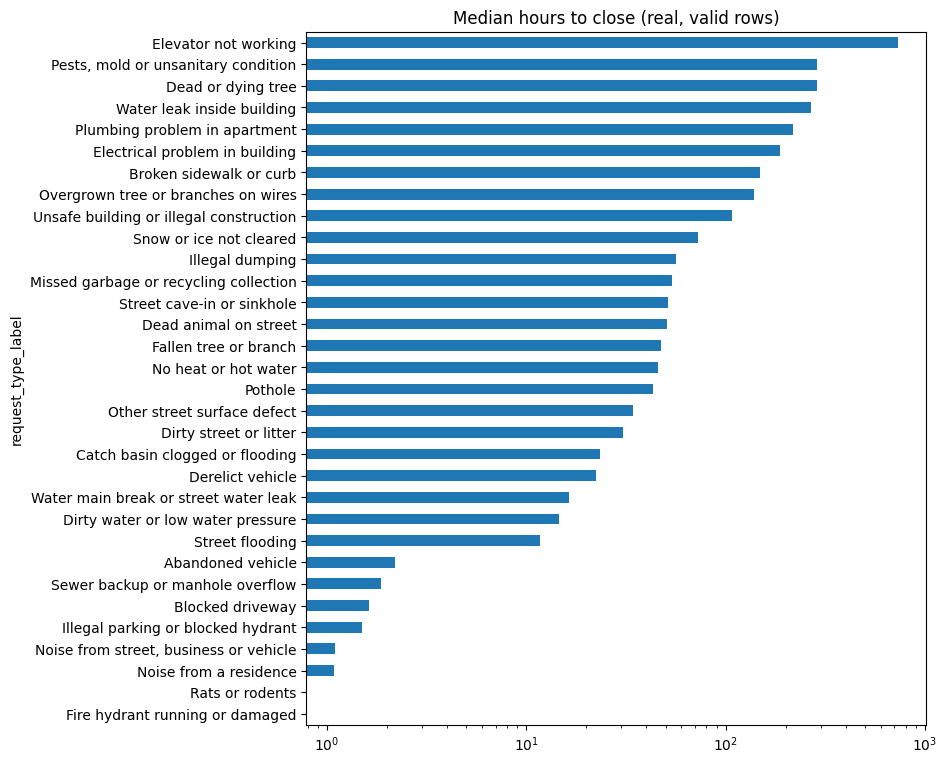

In [6]:
v = real[real.resolution_valid]
v.groupby("request_type_label").resolution_hours.median().sort_values().plot.barh(figsize=(8, 9), logx=True,
    title="Median hours to close (real, valid rows)");

## 4 · The leakage rules (read carefully)
| Column | Allowed as model input? | Why |
|---|---|---|
| `resolution_description`, `outcome_class`, `verified_outcome` | **No, label only** | Not known when a request arrives |
| `closed_date`, `resolution_hours`, `status` | **No, label only** | Future information |
| `hidden_honesty` (synthetic citizens) | **Never, evaluation only** | It is the answer key for C07 |
| `split` | Use it | Time-based 70/15/15. Everybody uses the same split |

In [7]:
assert set(real.split) == {"train", "val", "test"}
assert real.groupby("split").created_at.max()["train"] <= real.groupby("split").created_at.min()["test"], "split must be by time"
print("time-based split OK:", real.split.value_counts().to_dict())

time-based split OK: {'train': 34690, 'val': 7434, 'test': 7434}


## 5 · Weather joined to every request (C08, C09, C10, C13)

In [8]:
real.groupby(pd.cut(real.wx_precip_mm, [-0.1, 0.5, 5, 15, 200]))["complaint_family"].value_counts(normalize=True).unstack().round(3)

C:\Users\Sankalp Indish\AppData\Local\Temp\ipykernel_25880\141365633.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  real.groupby(pd.cut(real.wx_precip_mm, [-0.1, 0.5, 5, 15, 200]))["complaint_family"].value_counts(normalize=True).unstack().round(3)


complaint_family,BUILDINGS,HEALTH,HOUSING,NOISE_PARKING,PARKS_TREES,SANITATION,STREETS,WATER_SEWER
wx_precip_mm,,,,,,,,
"(-0.1, 0.5]",0.023,0.008,0.222,0.466,0.030,0.123,0.091,0.038
"(0.5, 5.0]",0.019,0.010,0.204,0.499,0.024,0.074,0.100,0.070
"(5.0, 15.0]",0.020,0.010,0.176,0.480,0.040,0.090,0.137,0.047
"(15.0, 200.0]",0.018,0.007,0.190,0.480,0.065,0.077,0.109,0.053


## 6 · Daily demand 2020+ (C13 training table)
Only present after the full download has finished.

C:\Users\Sankalp Indish\AppData\Local\Temp\ipykernel_25880\2736447076.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ws.groupby(pd.cut(ws.wx_precip_mm, [-0.1, 1, 10, 25, 50, 300]))["n"].mean().plot.bar(title="Water/sewer requests per borough-day vs rain (mm)")


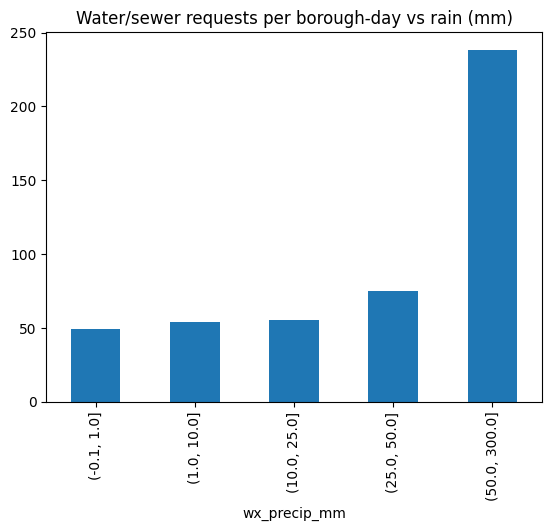

In [9]:
dd_path = P / "daily_demand_weather.parquet"
if dd_path.exists():
    dd = pd.read_parquet(dd_path)
    ws = dd[dd.complaint_family == "WATER_SEWER"]
    ws.groupby(pd.cut(ws.wx_precip_mm, [-0.1, 1, 10, 25, 50, 300]))["n"].mean().plot.bar(title="Water/sewer requests per borough-day vs rain (mm)")
else:
    print("daily_demand_weather.parquet not built yet (download step B still running)")

## 7 · The ONE shared synthetic population
Generated once and shared by C05, C06, C07, C10, C11 and C12, so the same citizen is the same person everywhere (as the proposal commits).

In [10]:
cit = pd.read_parquet(P / "synthetic_citizens.parquet")
links = pd.read_parquet(P / "synthetic_reporter_links.parquet")
display(cit.archetype.value_counts())
# sanity: hidden honesty agrees with the real outcomes each citizen was linked to
j = links.merge(real[["request_id", "verified_outcome"]], on="request_id").merge(cit, on="citizen_id")
obs = j[j.verified_outcome != "INCONCLUSIVE"].groupby("citizen_id").agg(n=("request_id", "size"),
        genuine=("verified_outcome", lambda s: (s == "GENUINE").mean()), honesty=("hidden_honesty", "first"))
print("corr(observed genuine rate, hidden honesty) for citizens with >=5 reports:",
      round(obs[obs.n >= 5][["genuine", "honesty"]].corr().iloc[0, 1], 3))

archetype
OCCASIONAL_HONEST      3487
FREQUENT_HONEST         613
FREQUENT_UNRELIABLE     390
NEW_HONEST              350
BURST_REPORTER          160
Name: count, dtype: int64

corr(observed genuine rate, hidden honesty) for citizens with >=5 reports: 0.891


In [11]:
crews = pd.read_parquet(P / "synthetic_crews.parquet")
print(len(crews), "synthetic crews")
crews.groupby(["borough", "agency"]).size().unstack(fill_value=0)

136 synthetic crews


agency,DEP,DOB,DOHMH,DOT,DPR,DSNY,HPD,NYPD
borough,,,,,,,,
BRONX,3,1,1,4,1,3,7,8
BROOKLYN,2,1,1,6,1,4,5,8
MANHATTAN,2,1,1,6,1,4,6,8
QUEENS,2,1,1,6,1,4,2,8
STATEN ISLAND,3,1,1,6,2,4,2,7


In [12]:
urg = pd.read_parquet(P / "synthetic_urgency_scenarios.parquet")
display(urg.urgency_ground_truth.value_counts())
urg[["request_type_label", "hazard_indicator", "people_at_risk", "urgency_ground_truth", "reviewer_rationale"]].head(8)

urgency_ground_truth
LOW         342
CRITICAL    300
MEDIUM      182
HIGH        176
Name: count, dtype: int64

,request_type_label,hazard_indicator,people_at_risk,urgency_ground_truth,reviewer_rationale
0,"Noise from street, business or vehicle",False,5,LOW,"base LOW for Noise from street, business or ve..."
1,No heat or hot water,False,5,CRITICAL,base HIGH for No heat or hot water; no heat be...
2,Broken sidewalk or curb,False,0,LOW,base LOW for Broken sidewalk or curb
3,No heat or hot water,True,12,CRITICAL,base HIGH for No heat or hot water; active haz...
4,Snow or ice not cleared,True,13,CRITICAL,base MEDIUM for Snow or ice not cleared; activ...
5,"Noise from street, business or vehicle",False,3,LOW,"base LOW for Noise from street, business or ve..."
6,Noise from a residence,False,0,LOW,base LOW for Noise from a residence
7,Noise from a residence,True,4,HIGH,base LOW for Noise from a residence; active ha...


In [13]:
qs = pd.read_parquet(P / "synthetic_queue_snapshots.parquet")
qs.groupby(["scenario", "eval_split"]).snapshot_id.nunique()

scenario  eval_split
NORMAL    test          22
          train         53
SURGE     test           8
          train         17
Name: snapshot_id, dtype: int64

## 8 · Which component uses which table
| Component (owner) | Tables |
|---|---|
| C01 NLP bot, C03 emergency (Sankalp) | `synthetic_nlp_utterances`, `reference/nlp_gold_test.csv`, `reference/emergency_lexicon.csv` |
| C02 profanity (Khalid) | `synthetic_nlp_utterances` (profanity column), `reference/profanity_lexicon.csv`, gold test |
| C04 agency routing (Mohammad) | `requests_real` (agency, outcome_class = REFERRED), `reference/request_catalog.csv`, `data/reference/NYC311_agency_matrix.md` |
| C05 duplicate (Nabeel) | `requests_real` (sample_window_id keeps dense windows), `synthetic_reporter_links` + a hand-labelled pair set |
| C06 fake (Nabeel) | `requests_real` (outcome_class), `synthetic_reporter_links`, `synthetic_citizens`, `synthetic_burst_requests` |
| C07 credibility (Sankalp) | `synthetic_citizens` (hidden_honesty for evaluation only), `synthetic_reporter_links`, `requests_real` |
| C08 external, C12 dispatch (Mohammad) | `requests_real` coordinates, OSM (built by the owner), `synthetic_crews` |
| C09 resolution time (Mohammad) | `requests_real` (resolution_hours where resolution_valid) |
| C10 urgency, C11 priority (Khalid) | `synthetic_urgency_scenarios`, `synthetic_queue_snapshots` |
| C13 alerting (Sankalp) | `daily_demand_weather`, `reference/demand_baselines.csv` |

## 9 · Small committed sample
`data/sample/` (a few MB) lets anyone run the contracts and component tests without downloading anything. Regenerated by `build.py`.

In [14]:
sorted(p.name for p in (ROOT / "01_Application" / "data" / "sample").glob("*.csv"))

['requests_real_sample.csv',
 'synthetic_citizens.csv',
 'synthetic_crews.csv',
 'synthetic_nlp_utterances_sample.csv',
 'synthetic_queue_snapshots_sample.csv',
 'synthetic_reporter_links_sample.csv',
 'synthetic_urgency_scenarios.csv']